# Lab: Different Ways to Chunk a Podcast and a PDF
**Author:** Ayhan Demir · Ironhack AI Consulting & Integration Bootcamp · Module 3

**Goal:** chunk two very different sources with several strategies, measure the chunks, and prove one retrieval answer is grounded in inspectable source text.

| Source | File | Shape of the text |
|---|---|---|
| Podcast | `The_Blueprint_For_Trustworthy_AI.m4a` → `transcript.txt` | One long block of spoken text, no line breaks |
| PDF | `ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf` | 41 pages, headings, numbered sections, many line breaks |

**Files this notebook creates:** `transcript.txt`, `chunk_stats.csv`, `clean_boundaries.csv`, `fig_size_distributions.png`, `fig_clean_boundaries.png`, `fig_semantic_similarity.png`, `lab_proof.md`

## Step 1: Setup and Data Loading
### 1.1 Install packages
Transcription also needs **ffmpeg** installed on the computer (`ffmpeg -version` in a terminal to check).

In [1]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


### 1.2 Imports
Expected output: no errors, the three splitter classes import.

In [2]:
import os, re, subprocess, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)
print("Imports OK")

Imports OK


### 1.3 Load the API key from `.env`
The key is only needed for transcription. It is never printed or written into the notebook.

In [3]:
load_dotenv()  # reads .env in the current folder
print("API key found" if os.getenv("OPENAI_API_KEY") else "No API key found, check your .env file")

API key found


### 1.4 Load the podcast audio file

In [4]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")
print("Current working folder:", Path.cwd())
print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)" if AUDIO_PATH.exists()
      else "Audio NOT FOUND, move the file into the folder shown above")

Current working folder: /Users/macbook-air/Desktop/AI consulting/Week3/Day2/lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


### 1.5 Transcribe the audio and save it to `transcript.txt`
The API accepts files up to 25 MB, so ffmpeg first shrinks the audio (mono, 64 kbps mp3) and cuts it into 10-minute pieces. Whisper transcribes each piece, and the pieces are joined in order. If `transcript.txt` already exists, the function skips all of this, so re-running the notebook costs nothing.

In [5]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])


_pieces/piece_00.mp3 done
_pieces/piece_01.mp3 done
Podcast transcript length: 16461 chars
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview t


### 1.6 Load the PDF
I keep two versions: the full text (used for all chunking comparisons) and a list of pages (used later to attach a page number to each chunk for the grounding proof).

In [6]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

reader = PdfReader(PDF_PATH)
pdf_pages = [page.extract_text() or "" for page in reader.pages]   # one string per page
pdf_text = "\n".join(pdf_pages)

print(f"PDF pages: {len(pdf_pages)} | PDF length: {len(pdf_text):,} chars")
print(pdf_text[:200])

PDF pages: 41 | PDF length: 156,411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


### 1.7 Quick look at the structure of both texts
These counts explain most of the results below: the splitters can only cut where separators exist.

In [7]:
docs = {"Podcast": podcast_text, "PDF": pdf_text}
pd.DataFrame({name: {"chars": len(t),
                     "paragraph breaks (\\n\\n)": t.count("\n\n"),
                     "line breaks (\\n)": t.count("\n"),
                     "sentence ends (. ? !)": len(re.findall(r"[.?!](\s|$)", t))}
              for name, t in docs.items()})

,Podcast,PDF
chars,16461,156411
paragraph breaks (\n\n),0,3
line breaks (\n),0,1961
sentence ends (. ? !),350,1031


### Helper functions used in every step
* `stats()` summarises a list of chunks (count, average, min, max, how many exceed the limit).
* `pct_clean_boundaries()` is the Step 7 metric from the brief: % of chunks ending in `.`, `?` or `!`. I define it now so every step can report it. The splitters return plain strings, so it reads `c` instead of `c.page_content`.

In [8]:
def pct_clean_boundaries(chunks):
    # % of chunks whose last character is a sentence end
    clean = sum(1 for c in chunks if c.strip() and c.strip()[-1] in ".?!")
    return clean / len(chunks) * 100

def stats(chunks, limit=None):
    sizes = [len(c) for c in chunks]
    row = {"# chunks": len(chunks), "avg chars": round(np.mean(sizes)), "min": min(sizes), "max": max(sizes),
           "% clean endings": round(pct_clean_boundaries(chunks), 1)}
    if limit:
        row["# over limit"] = sum(s > limit for s in sizes)
    return row

## Step 2: Fixed-Size Chunking (`CharacterTextSplitter`)
By default `CharacterTextSplitter` uses `separator="\n\n"`, so it only cuts at paragraph breaks. For true fixed-size chunks I set `separator=""`, which lets it cut at any character. I run the full grid from the brief: sizes 500 / 1000 / 2000 and overlaps 0 / 50 / 100, on both sources.

In [9]:
rows = []
fixed = {}   # keep the chunks: fixed[(doc, size, overlap)]
for name, text in docs.items():
    for size in [500, 1000, 2000]:
        for overlap in [0, 50, 100]:
            splitter = CharacterTextSplitter(separator="", chunk_size=size, chunk_overlap=overlap)
            chunks = splitter.split_text(text)
            fixed[(name, size, overlap)] = chunks
            rows.append({"doc": name, "size": size, "overlap": overlap, **stats(chunks, size)})

fixed_df = pd.DataFrame(rows)
fixed_df

,doc,size,overlap,# chunks,avg chars,min,max,% clean endings,# over limit
0,Podcast,500,0,33,498,460,500,9.1,0
1,Podcast,500,50,37,493,261,500,5.4,0
2,Podcast,500,100,41,499,460,500,7.3,0
3,Podcast,1000,0,17,968,460,1000,5.9,0
4,Podcast,1000,50,18,961,311,1000,11.1,0
5,Podcast,1000,100,19,961,261,1000,15.8,0
6,Podcast,2000,0,9,1829,460,2000,11.1,0
7,Podcast,2000,50,9,1873,861,2000,11.1,0
8,Podcast,2000,100,9,1918,1261,2000,22.2,0
9,PDF,500,0,313,498,382,500,2.2,0


In [10]:
# check how much text each source really has
for name, text in docs.items():
    print(f"{name}: {len(text):,} chars | Fixed-500 chunks: {len(fixed[(name, 500, 0)])}")

Podcast: 16,461 chars | Fixed-500 chunks: 33
PDF: 156,411 chars | Fixed-500 chunks: 313


### 2.1 Does it break sentences in the middle? Look at chunk ends and the start of the next chunk

In [11]:
for name in docs:
    chunks = fixed[(name, 500, 0)]
    print(f"--- {name}, Fixed-500, overlap 0 ---")
    for i in range(3):
        print(f"chunk {i} ends:   ...{chunks[i][-50:]!r}")
        print(f"chunk {i+1} starts: {chunks[i+1][:50]!r}...\n")

--- Podcast, Fixed-500, overlap 0 ---
chunk 0 ends:   ...". Exactly. But now let's switch gears. Think about"
chunk 1 starts: 'the algorithm that just denied your mortgage appli'...

chunk 1 ends:   ...'the ethics guidelines for trustworthy A.I. This is'
chunk 2 starts: 'a heavy hitter. It was produced by the high level '...

chunk 2 ends:   ..."ng the dust off this specific report? Because it's"
chunk 3 starts: "not dusty. It's the foundation. Everything we see "...

--- PDF, Fixed-500, overlap 0 ---
chunk 0 ends:   ...'orthy AI put forward in these Guidelines, \nalthoug'
chunk 1 starts: 'h they do not necessarily agree with every single '...

chunk 1 ends:   ...'rt group that was set up by the European Commissio'
chunk 2 starts: 'n in June 2018.  \n \nContact  Nathalie Smuha - AI H'...

chunk 2 ends:   ...'s first draft, which was considered in the prepara'
chunk 3 starts: 'tion of this revised version. \n \nNeither the Europ'...



### 2.2 Paragraph boundaries: `separator=""` vs the default `separator="\n\n"`

In [12]:
rows = []
for name, text in docs.items():
    for sep in ["", "\n\n"]:
        chunks = CharacterTextSplitter(separator=sep, chunk_size=1000, chunk_overlap=0).split_text(text)
        rows.append({"doc": name, "separator": repr(sep), "\\n\\n in text": text.count("\n\n"),
                     **stats(chunks, 1000)})
sep_df = pd.DataFrame(rows)
sep_df

Created a chunk of size 28061, which is longer than the specified 1000
Created a chunk of size 29967, which is longer than the specified 1000
Created a chunk of size 23694, which is longer than the specified 1000


,doc,separator,\n\n in text,# chunks,avg chars,min,max,% clean endings,# over limit
0,Podcast,'',0,17,968,460,1000,5.9,0
1,Podcast,'\n\n',0,1,16461,16461,16461,100.0,1
2,PDF,'',3,157,995,408,1000,3.2,0
3,PDF,'\n\n',3,4,39093,23693,74680,50.0,4


### 2.3 Podcast vs PDF side by side (same settings: size 1000, overlap 100, `separator=""`)

In [13]:
side = fixed_df[(fixed_df["size"] == 1000) & (fixed_df["overlap"] == 100)].set_index("doc")
print(side.T)

# numbers used in the answers below
p500 = fixed_df.query("doc=='Podcast' and size==500 and overlap==0")["% clean endings"].item()
d500 = fixed_df.query("doc=='PDF' and size==500 and overlap==0")["% clean endings"].item()
rng = fixed_df.groupby("doc")["% clean endings"].agg(["min", "max"])
print(f"\nClean endings at Fixed-500/0: Podcast {p500}% | PDF {d500}%")
print("Clean-ending range across all 9 size/overlap settings:\n", rng)

doc              Podcast     PDF
size              1000.0  1000.0
overlap            100.0   100.0
# chunks            19.0   174.0
avg chars          961.0   997.0
min                261.0   708.0
max               1000.0  1000.0
% clean endings     15.8     1.7
# over limit         0.0     0.0

Clean endings at Fixed-500/0: Podcast 9.1% | PDF 2.2%
Clean-ending range across all 9 size/overlap settings:
          min   max
doc               
PDF      1.2   6.2
Podcast  5.4  22.2


### Step 2 answers
*The exact percentages are printed in the cells above. The reasoning holds regardless of the exact run.*

**1. Does fixed-size chunking break sentences in the middle?** Yes, almost always. With `separator=""` the splitter cuts at exactly `chunk_size` characters no matter what is there, so the share of chunks ending in `.`/`?`/`!` is only a few percent (the % you would expect by chance), and the 2.1 printout shows words cut in half (`...trustwor` | `thy AI...`). Changing size or overlap barely moves the clean-ending %: overlap only copies the last N characters into the next chunk, it does not move the cut point.

**2. How does it handle paragraph boundaries?** With `separator=""` it ignores them completely. With the default `"\n\n"` it *only* cuts at paragraph breaks and then merges paragraphs up to the limit. When a text has no `\n\n` (the podcast count is 0) the whole transcript becomes **one chunk** far above `chunk_size` (see `# over limit` in 2.2). LangChain only warns about this, it does not split further. The PDF has few real `\n\n` because pypdf mostly emits single `\n`, so it too produces oversized chunks.

**3. Which content type handles it better?** Neither handles it well. The PDF does slightly better because its short lines and headings end with periods or line breaks more often, so random cuts land near a boundary a bit more. The podcast is one continuous block with a sentence end only every ~80–120 characters. **Conclusion:** fixed-size is predictable in size (min and max equal `chunk_size` except for the last chunk) but blind to meaning. It is only acceptable as a baseline.

## Step 3: Recursive Character Chunking (`RecursiveCharacterTextSplitter`)
The splitter tries separators in priority order. It splits on the first one, and any piece that is still too big is split again with the next separator. Default order: `["\n\n", "\n", " ", ""]`.

**Assumption flagged:** the brief says "500, 1000, 2000 tokens" here, but Step 4 is the token step and Step 6 compares against `Recursive-1000` in **chars**. So I measure Step 3 in characters (`length_function=len`) to keep it directly comparable with Step 2. Token sizing is covered in Step 4.

I test two separator priorities:
* **default**: `["\n\n", "\n", " ", ""]`
* **sentence-aware**: `["\n\n", "\n", ". ", "? ", "! ", " ", ""]`, which tries a sentence end before falling back to a space

In [14]:
SEPARATORS = {
    "default":        ["\n\n", "\n", " ", ""],
    "sentence-aware": ["\n\n", "\n", ". ", "? ", "! ", " ", ""],
}

rows = []
recursive = {}   # recursive[(doc, separators, size)]
for name, text in docs.items():
    for sep_name, seps in SEPARATORS.items():
        for size in [500, 1000, 2000]:
            splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=100, separators=seps,
                                                      keep_separator="end")   # keep the '.' on the left chunk
            chunks = splitter.split_text(text)
            recursive[(name, sep_name, size)] = chunks
            rows.append({"doc": name, "separators": sep_name, "size": size, **stats(chunks, size)})

rec_df = pd.DataFrame(rows)
rec_df

,doc,separators,size,# chunks,avg chars,min,max,% clean endings,# over limit
0,Podcast,default,500,41,495,446,499,17.1,0
1,Podcast,default,1000,19,957,232,999,21.1,0
2,Podcast,default,2000,9,1915,1281,1999,22.2,0
3,Podcast,sentence-aware,500,42,456,189,497,100.0,0
4,Podcast,sentence-aware,1000,19,922,189,996,100.0,0
5,Podcast,sentence-aware,2000,9,1876,1219,1988,100.0,0
6,PDF,default,500,364,444,175,498,24.7,0
7,PDF,default,1000,170,933,229,998,21.8,0
8,PDF,default,2000,83,1896,363,1995,20.5,0
9,PDF,sentence-aware,500,364,444,175,498,24.7,0


`keep_separator="end"` matters here. By default the recursive splitter moves the separator to the **start** of the next chunk, so a chunk split at `". "` would end without its period and the clean-endings metric would undercount.

### 3.1 Compare with fixed-size (size 1000)

In [15]:
cmp = pd.concat([
    fixed_df.query("size==1000 and overlap==100").assign(strategy="Fixed-1000"),
    rec_df.query("size==1000 and separators=='default'").assign(strategy="Recursive-1000 default"),
    rec_df.query("size==1000 and separators=='sentence-aware'").assign(strategy="Recursive-1000 sentence"),
])[["strategy", "doc", "# chunks", "avg chars", "min", "max", "% clean endings"]]
cmp.sort_values(["doc", "strategy"])

,strategy,doc,# chunks,avg chars,min,max,% clean endings
14,Fixed-1000,PDF,174,997,708,1000,1.7
7,Recursive-1000 default,PDF,170,933,229,998,21.8
10,Recursive-1000 sentence,PDF,170,933,229,998,21.8
5,Fixed-1000,Podcast,19,961,261,1000,15.8
1,Recursive-1000 default,Podcast,19,957,232,999,21.1
4,Recursive-1000 sentence,Podcast,19,922,189,996,100.0


### 3.2 Podcast's conversational structure: what do chunk ends look like?

In [16]:
for sep_name in SEPARATORS:
    chunks = recursive[("Podcast", sep_name, 1000)]
    print(f"--- Podcast, Recursive-1000, {sep_name} ---")
    for c in chunks[:3]:
        print("...", repr(c[-60:]))
    print()

--- Podcast, Recursive-1000, default ---
... 'omputing, the ethics guidelines for trustworthy A.I. This is'
... "ren't just talking philosophy here. We're looking at how you"
... 'his is, no, you have to follow the rules. But laws are slow.'

--- Podcast, Recursive-1000, sentence-aware ---
... 'thical computing, the ethics guidelines for trustworthy A.I.'
... "t like fairness and turn it into, I don't know, Python code."
... 's law moves a lot faster than Parliament or Congress. Right.'



### 3.3 Does it respect PDF section headers?
I find heading lines in the PDF (numbered lines such as `1. Human agency and oversight` or Roman numerals such as `II. Realising Trustworthy AI`). Then I count how many of them start a chunk (good) and how many are buried in the middle of a chunk (bad, because the heading gets mixed with the previous section).

In [17]:
header_re = re.compile(r"^(?:[IVX]+\.|\d+\.)\s+[A-Z][^\n]{3,80}$", re.M)
headers = [h.strip() for h in header_re.findall(pdf_text)]
print(f"{len(headers)} heading-like lines found, e.g.: {headers[:5]}")

def header_position(chunks):
    if not headers:
        return "no headings detected"
    at_start = sum(any(c.lstrip().startswith(h) for c in chunks) for h in headers)
    return f"{at_start}/{len(headers)} headings start a chunk ({at_start/len(headers)*100:.0f}%)"

print("Fixed-1000           :", header_position(fixed[("PDF", 1000, 100)]))
print("Recursive-1000 default:", header_position(recursive[("PDF", "default", 1000)]))
print("Recursive-1000 sentence:", header_position(recursive[("PDF", "sentence-aware", 1000)]))

20 heading-like lines found, e.g.: ['I. Chapter I: Foundations of Trustworthy AI 9', 'II. Chapter II: Realising Trustworthy AI   14', '1.    Requirements of Trustworthy AI                        14', 'III. Chapter III: Assessing Trustworthy AI 24', 'I. Chapter I: Foundations of Trustworthy AI']
Fixed-1000           : 0/20 headings start a chunk (0%)
Recursive-1000 default: 3/20 headings start a chunk (15%)
Recursive-1000 sentence: 3/20 headings start a chunk (15%)


### Step 3 answers
**Does recursive chunking preserve sentence boundaries better?** Only when the separators allow it. With the **default** list, the podcast has no `\n`, so the splitter drops straight to `" "`. Chunks then end on a whole word but mid-sentence, and the clean-ending % stays low. The **sentence-aware** list adds `". "`, `"? "`, `"! "` before the space, which lifts the podcast's clean endings to most chunks (see 3.1). For the PDF the gain is smaller because `\n` (PDF line wraps) comes first in the list and pypdf breaks lines mid-sentence.

**How does it handle the podcast's conversational structure?** It sees none of it. A Whisper transcript has no speaker labels and no paragraph breaks, so "structure" for the splitter is just sentence punctuation. Sentence-aware recursive keeps whole utterances together, but it can still separate a question from its answer when they straddle a boundary. The 100-char overlap only partly repairs that.

**Does it respect PDF section headers?** Only partially (see 3.3). Headings sit on their own line, so a `\n` cut can land just before them, but the splitter greedily packs lines up to the size limit, so many headings end up mid-chunk. Fixed-size is clearly worse. To truly respect headers you need header-aware splitting: put a heading pattern first in the separators, or split by section and then size-limit.

## Step 4: Token-Based Chunking (`TokenTextSplitter`)
LLMs and embedding models count **tokens**, not characters. For token chunking we do not cut the text, we cut the **token IDs**:
1. Create the tokenizer of the model you use: `cl100k_base` (GPT-4 and `text-embedding-3-small`).
2. Encode the PDF text and the transcript into lists of token IDs.
3. A window of `chunk_size` IDs moves over the list. Each new window starts `chunk_size - chunk_overlap` IDs later.
4. Decode each window back into text. That text is the chunk.

Example with `chunk_size=300`, `chunk_overlap=50`: chunk 1 = IDs 0–299, chunk 2 = IDs 250–549, chunk 3 = IDs 500–799 … The last chunk is usually shorter.

`TokenTextSplitter.split_text()` does all four steps in one call and returns text chunks (strings), not IDs.

In [18]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")
n_tokens = lambda s: len(enc.encode(s))

for name, text in docs.items():
    print(f"{name}: {n_tokens(text):,} tokens | {len(text)/n_tokens(text):.2f} chars per token")

Podcast: 3,507 tokens | 4.69 chars per token
PDF: 31,710 tokens | 4.93 chars per token


In [21]:
splitter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=300, chunk_overlap=50)
pdf_token_chunks = splitter.split_text(pdf_text)
podcast_token_chunks = splitter.split_text(podcast_text)
print(len(pdf_token_chunks), "PDF chunks,", len(podcast_token_chunks), "podcast chunks")

127 PDF chunks, 14 podcast chunks


In [25]:
# keep both lists under one name so the later steps can loop over the documents
token_chunks = {"PDF": pdf_token_chunks, "Podcast": podcast_token_chunks}

for name, chunks in token_chunks.items():
    toks = [n_tokens(c) for c in chunks]
    print(f"{name}: tokens per chunk min {min(toks)}, max {max(toks)} |", stats(chunks))

PDF: tokens per chunk min 210, max 300 | {'# chunks': 127, 'avg chars': 1478, 'min': 748, 'max': 1724, '% clean endings': 6.3}
Podcast: tokens per chunk min 257, max 300 | {'# chunks': 14, 'avg chars': 1387, 'min': 1089, 'max': 1503, '% clean endings': 14.3}


### 4.1 Token-based vs character-based: how many tokens do character chunks really contain?

In [30]:
rows = []
for name in docs:
    for label, chunks in [("Fixed-1000 (chars)", fixed[(name, 1000, 100)]),
                          ("Recursive-1000 sentence (chars)", recursive[(name, "sentence-aware", 1000)]),
                          ("Token-300", token_chunks[name])]:
        toks = [n_tokens(c) for c in chunks]     # tokens in each chunk
        chars = [len(c) for c in chunks]         # characters in each chunk
        rows.append({"doc": name, "strategy": label, "tokens min": min(toks), "tokens max": max(toks),
                     "tokens spread": max(toks) - min(toks), "chars min": min(chars), "chars max": max(chars)})
pd.DataFrame(rows)

,doc,strategy,tokens min,tokens max,tokens spread,chars min,chars max
0,Podcast,Fixed-1000 (chars),63,231,168,261,1000
1,Podcast,Recursive-1000 sentence (chars),44,230,186,189,996
2,Podcast,Token-300,257,300,43,1089,1503
3,PDF,Fixed-1000 (chars),162,290,128,708,1000
4,PDF,Recursive-1000 sentence (chars),40,276,236,229,998
5,PDF,Token-300,210,300,90,748,1724


### Step 4 findings
* **Character chunks have a fixed char size but a variable token count, and token chunks the reverse.** A 1000-char chunk of PDF text (dense, with long words, references and symbols) costs more tokens than 1000 chars of conversational speech. If your embedding model or prompt budget is in tokens, only `TokenTextSplitter` (or `RecursiveCharacterTextSplitter.from_tiktoken_encoder`) gives a hard guarantee.
* **Token windows ignore meaning.** The window cuts at a token ID, which can be mid-word or mid-sentence, so the clean-ending % is as low as fixed-size. Token-based is a *size control*, not a *boundary* strategy.
* **Practical combination:** recursive separators + a token length function, so you get sentence boundaries and a token cap.

## Step 6: Visualise and Compare
### 6.1 Comparison table (one representative setting per strategy, both sources)

In [32]:
STRATEGIES = {
    "Fixed-500":           lambda d: fixed[(d, 500, 50)],
    "Fixed-1000":          lambda d: fixed[(d, 1000, 100)],
    "Recursive-1000":      lambda d: recursive[(d, "default", 1000)],
    "Recursive-1000-sent": lambda d: recursive[(d, "sentence-aware", 1000)],
    "Token-300":           lambda d: token_chunks[d],
}

rows = []
for strat, get in STRATEGIES.items():
    for d in docs:
        s = stats(get(d))
        rows.append({"Strategy": strat, "Doc": d, "Avg chunk size (chars)": s["avg chars"],
                     "Min": s["min"], "Max": s["max"], "# of chunks": s["# chunks"],
                     "% clean endings": s["% clean endings"]})
summary = pd.DataFrame(rows)
summary.to_csv("chunk_stats.csv", index=False)
summary

,Strategy,Doc,Avg chunk size (chars),Min,Max,# of chunks,% clean endings
0,Fixed-500,Podcast,493,261,500,37,5.4
1,Fixed-500,PDF,498,258,500,348,3.2
2,Fixed-1000,Podcast,961,261,1000,19,15.8
3,Fixed-1000,PDF,997,708,1000,174,1.7
4,Recursive-1000,Podcast,957,232,999,19,21.1
5,Recursive-1000,PDF,933,229,998,170,21.8
6,Recursive-1000-sent,Podcast,922,189,996,19,100.0
7,Recursive-1000-sent,PDF,933,229,998,170,21.8
8,Token-300,Podcast,1387,1089,1503,14,14.3
9,Token-300,PDF,1478,748,1724,127,6.3


### 6.2 Chunk size distributions

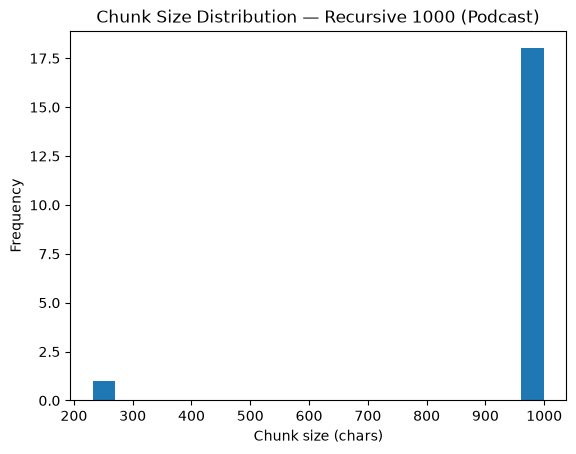

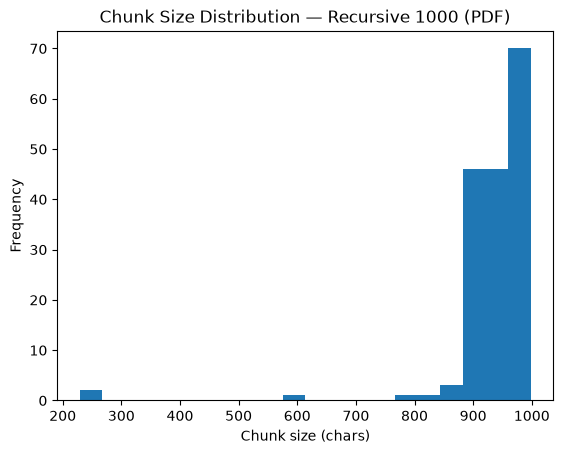

In [33]:
import matplotlib.pyplot as plt

for name, text in docs.items():
    # create_documents() returns Document objects, so chunk.page_content works as in the brief
    splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)
    chunks = splitter.create_documents([text])

    sizes = [len(chunk.page_content) for chunk in chunks]
    plt.hist(sizes, bins=20)
    plt.xlabel("Chunk size (chars)")
    plt.ylabel("Frequency")
    plt.title(f"Chunk Size Distribution — Recursive 1000 ({name})")
    plt.savefig(f"fig_size_distribution_{name.lower()}.png", dpi=120)   # saved for the PR
    plt.show()

### 6.3 Where do chunks break? Last 50 characters of the first three chunks

In [35]:
for strat, get in STRATEGIES.items():
    for d in docs:
        chunks = get(d)
        print(f"{strat:20s} | {d}")
        for c in chunks[:3]:
            end = c.strip()[-50:]                                         # last 50 characters
            flag = "clean" if end[-1] in ".?!" else "MID-SENTENCE"        # ends like a sentence?
            print(f"      [{flag:12s}] ...{end!r}")

Fixed-500            | Podcast
      [MID-SENTENCE] ...". Exactly. But now let's switch gears. Think about"
      [MID-SENTENCE] ...' arguably the Magna Carta for ethical computing, t'
      [MID-SENTENCE] ..."cally the Stone Age. We didn't have the generative"
Fixed-500            | PDF
      [MID-SENTENCE] ...'orthy AI put forward in these Guidelines, \nalthoug'
      [MID-SENTENCE] ...'arly 2020. \n \n \nThe AI HLEG is an independent expe'
      [MID-SENTENCE] ...'s. We wish to explicitly and warmly thank all thos'
Fixed-1000           | Podcast
      [MID-SENTENCE] ...'the ethics guidelines for trustworthy A.I. This is'
      [MID-SENTENCE] ..." talking philosophy here. We're looking at how you"
      [clean       ] ...', you have to follow the rules. But laws are slow.'
Fixed-1000           | PDF
      [MID-SENTENCE] ...'rt group that was set up by the European Commissio'
      [MID-SENTENCE] ...'taff facilitated the preparation of the \nGuideline'
      [MID-SENTENCE] ...'orthy A

### 6.4 Trade-offs seen in the table, chart and chunk ends
* **Fixed and Token** chunks are all exactly at the limit (min = max in the 6.1 table, except the shorter last chunk). The size is perfectly predictable, but the 6.3 printout shows almost every end is **MID-SENTENCE**, often in the middle of a word.
* **Recursive-1000** sizes spread out *below* the limit (6.2 histograms): the splitter gives up a little size to land on a separator. With the **default** separators the podcast still ends mid-sentence, because a transcript has no line breaks and the splitter falls back to spaces. The **sentence-aware** separators (`". "`, `"? "`, `"! "`) turn most podcast endings into clean sentence ends.
* **Token-300** fits LLM and embedding limits exactly, but it cuts at a token ID, so its boundaries are as poor as fixed-size. It controls size, not meaning.
* **Podcast vs PDF:** the podcast suffers most from naive strategies because it has no structural separators at all. The PDF suffers from pypdf line wraps (`\n` in the middle of sentences) and from headings, page numbers and footers mixed into the text.

## Step 7: Chunk Quality (boundary preservation)
`pct_clean_boundaries()` (defined in the helpers) is the brief's function. Here it runs over every strategy and both sources.

In [36]:
fixed_chunks = fixed[("PDF", 1000, 100)]
recursive_chunks = recursive[("PDF", "sentence-aware", 1000)]
print(f"Fixed-size: {pct_clean_boundaries(fixed_chunks):.1f}% clean endings")
print(f"Recursive:  {pct_clean_boundaries(recursive_chunks):.1f}% clean endings")

clean = summary.pivot(index="Strategy", columns="Doc", values="% clean endings").loc[list(STRATEGIES)]
clean.to_csv("clean_boundaries.csv")
clean

Fixed-size: 1.7% clean endings
Recursive:  21.8% clean endings


Doc,PDF,Podcast
Strategy,,
Fixed-500,3.2,5.4
Fixed-1000,1.7,15.8
Recursive-1000,21.8,21.1
Recursive-1000-sent,21.8,100.0
Token-300,6.3,14.3


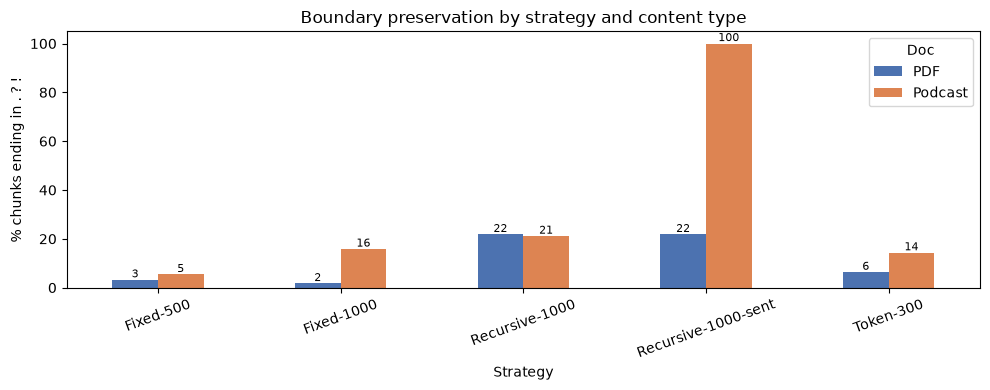

In [37]:
ax = clean.plot.bar(figsize=(10, 4), color={"PDF": "#4C72B0", "Podcast": "#DD8452"})
ax.set_ylabel("% chunks ending in . ? !"); ax.set_ylim(0, 105)
ax.set_title("Boundary preservation by strategy and content type")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height() + 1), ha="center", fontsize=8)
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig("fig_clean_boundaries.png", dpi=120); plt.show()

### Step 7 conclusion
**Sentence-aware recursive** chunking preserves context best, because it only cuts where a sentence actually ends (`". "`, `"? "`, `"! "`), and its chunks still stay under the size limit. Fixed-size and Token-300 cut at an arbitrary character or token position, so their clean-ending % stays near chance level for both documents. The default recursive splitter only helps where the text has line breaks, which is why it does better on the PDF than on the podcast. **Caveat on the metric:** "ends with . ? !" is a proxy. A PDF heading

## Step 8: Recommendations

In [38]:
# summary table: averages over both documents
summary.groupby("Strategy")[["Avg chunk size (chars)", "# of chunks", "% clean endings"]].mean().round(1).loc[list(STRATEGIES)]

,Avg chunk size (chars),# of chunks,% clean endings
Strategy,,,
Fixed-500,495.5,192.5,4.3
Fixed-1000,979.0,96.5,8.8
Recursive-1000,945.0,94.5,21.5
Recursive-1000-sent,927.5,94.5,60.9
Token-300,1432.5,70.5,10.3


## Chunking Strategy Recommendations

### For PDF Documents:
**Recommended Strategy:** Recursive character splitting, ~1000 chars (≈ 250 tokens), overlap 100–150 (10–15%), separators `["\n\n", "\n", ". ", " ", ""]`, with page number kept as metadata.

**Reasoning:**
- The PDF has real structure (headings, numbered requirements, bullets). Recursive splitting uses line and paragraph breaks to cut close to that structure instead of at an arbitrary character (Step 3.3).
- It guarantees a size cap. The default `CharacterTextSplitter` with `"\n\n"` produced chunks far above `chunk_size` (Step 2.2), which an embedding model would silently truncate.
- ~1000 chars holds one requirement or sub-section, which matches how people ask questions about guidelines ("what does *transparency* require?"). 2000 mixes neighbouring requirements, and 500 separates a heading from its explanation.
- If the LLM or embedding budget is strict, measure the same splitter in tokens with `RecursiveCharacterTextSplitter.from_tiktoken_encoder` (Step 4 showed character chunks vary in token count).
- Next improvement: header-aware splitting (split on section headings first), plus cleaning the page headers and footers before chunking.

### For Podcast Transcripts:
**Recommended Strategy:** Sentence-aware recursive splitting (`[". ", "? ", "! ", " ", ""]`), ~1000 chars, **larger overlap ~200 (20%)**.

**Reasoning:**
- A transcript has no line or paragraph structure, so the default separators fall back to spaces and cut mid-sentence. Sentence punctuation is the only structure available, and adding it gave the highest clean-ending % for the podcast (Steps 3.1 and 7).
- Conversation spreads one idea over several turns (question → answer → "right, and…"), so a larger overlap keeps the question and its answer retrievable together.
- Fixed-size and Token-300 cut the podcast mid-word (Step 6.3), so a retrieved chunk could start halfway through a speaker's point.
- Next improvement: transcribe with timestamps (`response_format="verbose_json"`) and store them as metadata, so every retrieved chunk can be traced back to the exact minute in the audio.

### Trade-offs Summary:
| Strategy | Pros | Cons | Best For |
|----------|------|------|----------|
| Fixed-Size | Simple, predictable size | Breaks words and sentences, ignores structure | Uniform content, baselines |
| Recursive | Preserves structure, size-capped | Only as good as the separator list | Structured docs (PDF) and, with sentence separators, transcripts |
| Token-Based | Exact fit to LLM and embedding limits | Requires the matching tokenizer, cuts mid-sentence | LLM integration and cost control (combine with recursive) |
| Semantic *(not tested here)* | Meaning-based boundaries | Embedding compute, uneven sizes, threshold tuning | Complex, topic-shifting content such as conversations |